# Productivity range
One productivity range per individual: the years between which they were active. It is taken from the first source available, in this order:

1. The first and last of the individual's work dates, cleaned with the rules of notebook 02, section 4.
2. "fl." in the Wikidata description with two dates ("fl. 1545–1565").

Only dates precise to the year or decade are used; a decade counts as its middle year. Ranges shorter than 2 years are removed: they point to a dating problem more than to a real productivity window. Wikidata values only.

In [1]:
import duckdb
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
FIRST_CENTURY = -1000
LAST_CENTURY = 2000
METHODS = ['First to last work date', '"fl." with two dates']
MIN_RANGE = 2
CUTOFF = 1500

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

connection = duckdb.connect(DB_PATH, read_only=True)
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')

13,002,897 individuals in the database


## Load the data
### 1. First and last cleaned work dates
The cleaning of notebook 02, section 4: lifetime check, publication dates checked against inceptions, inception spans over 100 years dropped. A decade date placed at its middle year is kept within the individual's birth and death.

In [2]:
LIFETIME_LIMIT = 100

connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
work_range = connection.execute('''
    WITH placed AS (
        SELECT qid,
               least(greatest(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END, coalesce(birth_year, -9999)),
                     coalesce(death_year, 9999)) AS year
        FROM clean_work
    )
    SELECT qid, min(year) AS start_year, max(year) AS end_year, count(*) AS works
    FROM placed
    GROUP BY qid
''').pl()
short = work_range.filter(pl.col('end_year') - pl.col('start_year') < MIN_RANGE)
work_range = work_range.filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{work_range.height:,} individuals with a work range of at least {MIN_RANGE} years')
print(f'{short.height:,} left out: range under {MIN_RANGE} years ({short.filter(pl.col("works") == 1).height:,} of them with a single work)')
work_range.sample(5, seed=0)

317,518 individuals with a work range of at least 2 years
267,375 left out: range under 2 years (232,402 of them with a single work)


qid,start_year,end_year,works
str,i64,i64,i64
"""Q3163161""",1979,2020,26
"""Q12375034""",2005,2011,4
"""Q10379705""",2015,2022,7
"""Q43091097""",2002,2019,37
"""Q52987928""",2013,2017,7


### 2. "fl." with two dates
Same parsing as notebooks 01 and 03; a shortened second year is completed from the first ("fl. 1840-60" → 1840 and 1860), except before the common era, where years count down ("fl. 104-89 BCE" → 104 and 89 BCE). "BC", "BCE", "B.C." all mark a date before the common era.

In [3]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'
range_pattern = r'\bfl\.[^,;)]*?\d\s*(?:s|st|nd|rd|th|\.)?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?\d'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
        pl.col('description').str.contains(range_pattern).alias('fl_range'),
    )
)
range_years_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})s?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})'


def second_year(match):
    first, second = match['1'], match['2']
    if first is None or second is None:
        return None
    if len(second) < len(first):
        second = first[:len(first) - len(second)] + second
    return int(second)


fl_text = fl_text.with_columns(
    pl.col('description').str.extract_groups(range_years_pattern)
    .map_elements(second_year, return_dtype=pl.Int64).alias('second_year'),
    pl.col('description').str.extract_groups(range_years_pattern).struct.field('2').cast(pl.Int64).alias('written_second_year'),
).with_columns(
    pl.when(pl.col('fl_year') < 0).then(-pl.col('written_second_year')).otherwise(pl.col('second_year')).alias('second_year')
).drop('written_second_year')
assert fl_text['qid'].is_unique().all()

fl_range = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid',
    pl.min_horizontal('fl_year', 'second_year').alias('start_year'),
    pl.max_horizontal('fl_year', 'second_year').alias('end_year'),
)
fl_short = fl_range.filter(pl.col('end_year') - pl.col('start_year') < MIN_RANGE)
fl_range = fl_range.filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{fl_range.height:,} individuals with a "fl." range of at least {MIN_RANGE} years ({fl_short.height:,} shorter ones left out)')
fl_range.sample(5, seed=0)

2,939 individuals with a "fl." range of at least 2 years (134 shorter ones left out)


qid,start_year,end_year
str,i64,i64
"""Q1291928""",1501,1521
"""Q135955862""",1537,1560
"""Q134347275""",1812,1820
"""Q104532728""",1957,1965
"""Q18681485""",1624,1634


## Assign the productivity range
Each individual takes the first method that gives a range.

In [4]:
sources = [work_range, fl_range]
productivity = (
    pl.concat([
        frame.select('qid', 'start_year', 'end_year').with_columns(pl.lit(method).alias('method'), pl.lit(rank).alias('rank'))
        for rank, (method, frame) in enumerate(zip(METHODS, sources))
    ])
    .sort('rank')
    .unique('qid', keep='first', maintain_order=True)
    .drop('rank')
    .with_columns(
        (pl.col('end_year') - pl.col('start_year')).alias('length'),
        ((pl.col('start_year') + pl.col('end_year')) // 2).alias('middle_year'),
    )
)
assert productivity['qid'].is_unique().all()
assert (productivity['length'] >= MIN_RANGE).all()
print(f'{productivity.height:,} individuals get a productivity range ({100 * productivity.height / database_size:.1f}% of the database)')
productivity['length'].describe()

320,404 individuals get a productivity range (2.5% of the database)


statistic,value
str,f64
"""count""",320404.0
"""null_count""",0.0
"""mean""",18.236592
"""std""",13.806981
"""min""",2.0
"""25%""",7.0
"""50%""",15.0
"""75%""",26.0
"""max""",717.0


## Table: individuals getting a productivity range by each method
"Available" counts every individual the method could give a range to; "Assigned" counts those it actually gives one to, after the method ranked above it. The period columns place each range by its middle year; their percentages are out of all ranges in that period.

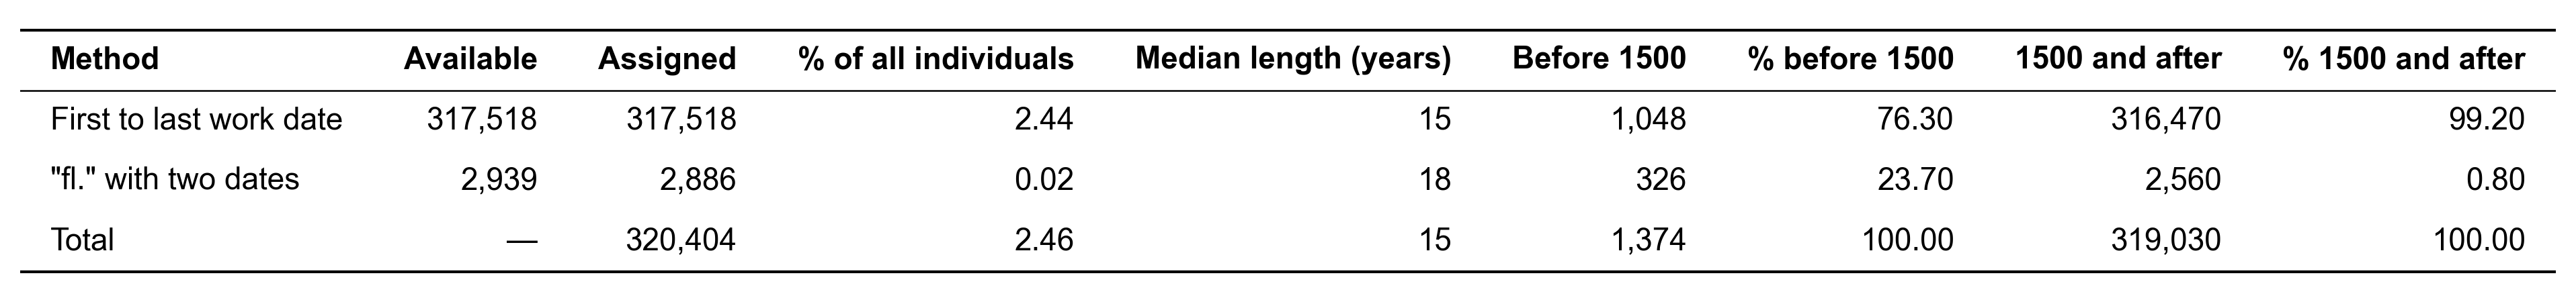

In [5]:
available = {method: frame.height for method, frame in zip(METHODS, sources)}
coverage = (
    productivity.group_by('method').agg(
        pl.len().alias('assigned'),
        pl.col('length').median().alias('median_length'),
        (pl.col('middle_year') < CUTOFF).sum().alias('before'),
        (pl.col('middle_year') >= CUTOFF).sum().alias('after'),
    )
    .with_columns(pl.col('method').replace_strict(available, return_dtype=pl.Int64).alias('available'))
    .sort(pl.col('method').replace_strict(METHODS, list(range(len(METHODS)))))
)
total = productivity.select(
    pl.lit('Total').alias('method'), pl.len().alias('assigned'), pl.col('length').median().alias('median_length'),
    (pl.col('middle_year') < CUTOFF).sum().alias('before'), (pl.col('middle_year') >= CUTOFF).sum().alias('after'),
    pl.lit(None, pl.Int64).alias('available'),
)
coverage = pl.concat([coverage, total.select(coverage.columns)], how='vertical_relaxed')
assert (coverage['before'] + coverage['after'] == coverage['assigned']).all()
before_total, after_total = total['before'][0], total['after'][0]
show_table(coverage.select(
    pl.col('method').alias('Method'),
    pl.col('available').alias('Available'),
    pl.col('assigned').alias('Assigned'),
    (100 * pl.col('assigned') / database_size).round(2).alias('% of all individuals'),
    pl.col('median_length').round(0).cast(pl.Int64).alias('Median length (years)'),
    pl.col('before').alias(f'Before {CUTOFF}'),
    (100 * pl.col('before') / before_total).round(1).alias(f'% before {CUTOFF}'),
    pl.col('after').alias(f'{CUTOFF} and after'),
    (100 * pl.col('after') / after_total).round(1).alias(f'% {CUTOFF} and after'),
), decimals=2)

## Testing: one individual per century
The individual with the most Wikimedia pages whose range starts in the century, with their Wikidata birth and death.

In [6]:
connection.register('productivity', productivity.to_arrow())
examples = connection.execute(f'''
    SELECT floor(productivity.start_year / 100)::BIGINT * 100 AS century,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || productivity.qid || ')' AS individual,
           coalesce(list_min([date.year FOR date IN individual.birth_date])::VARCHAR, '?') || ' – '
               || coalesce(list_min([date.year FOR date IN individual.death_date])::VARCHAR, '?') AS lifetime,
           productivity.start_year, productivity.end_year, productivity.length, productivity.method, productivity.qid
    FROM productivity
    JOIN individual ON individual.entity.qid = productivity.qid
    WHERE floor(productivity.start_year / 100) * 100 BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
    QUALIFY row_number() OVER (PARTITION BY floor(productivity.start_year / 100) ORDER BY len(individual.sitelink) DESC, productivity.qid) = 1
    ORDER BY century
''').pl()
examples

century,individual,lifetime,start_year,end_year,length,method,qid
i64,str,str,i64,i64,i64,str,str
-600,"""Exekias (Q358541)""","""-501 – -501""",-543,-529,14,"""First to last work date""","""Q358541"""
-500,"""Sophocles (Q7235)""","""-495 – -405""",-462,-441,21,"""First to last work date""","""Q7235"""
-400,"""Plato (Q859)""","""-428 – -348""",-390,-355,35,"""First to last work date""","""Q859"""
-300,"""Archimedes (Q8739)""","""-286 – -211""",-245,-224,21,"""First to last work date""","""Q8739"""
-200,"""Cato the Elder (Q180081)""","""-233 – -148""",-185,-155,30,"""First to last work date""","""Q180081"""
-100,"""Julius Caesar (Q1048)""","""-99 – -43""",-58,-48,10,"""First to last work date""","""Q1048"""
0,"""Paul the Apostle (Q9200)""","""5 – 66""",50,54,4,"""First to last work date""","""Q9200"""
100,"""Ptolemy (Q34943)""","""100 – 170""",148,155,7,"""First to last work date""","""Q34943"""
200,"""Caracalla (Q1446)""","""188 – 217""",211,216,5,"""First to last work date""","""Q1446"""


### Sanity check: ranges longer than a lifetime
Ranges over 100 years cannot be one person's activity; there should be almost none.

In [7]:
print(f"{productivity.filter(pl.col('length') > 100).height:,} ranges longer than 100 years")
productivity.filter(pl.col('length') > 100).group_by('method').len()

7 ranges longer than 100 years


method,len
str,u32
"""First to last work date""",2
"""""fl."" with two dates""",5


### Table: one productivity range per century, with an assessment
The assessment compares the range with the individual's best-known period of activity. It was written by Claude from general historical knowledge, not checked against sources: **Yes** = the range covers the main period of activity, **Partial** = inside it but much shorter, **Wrong start** / **Wrong end** = one end falls outside it.

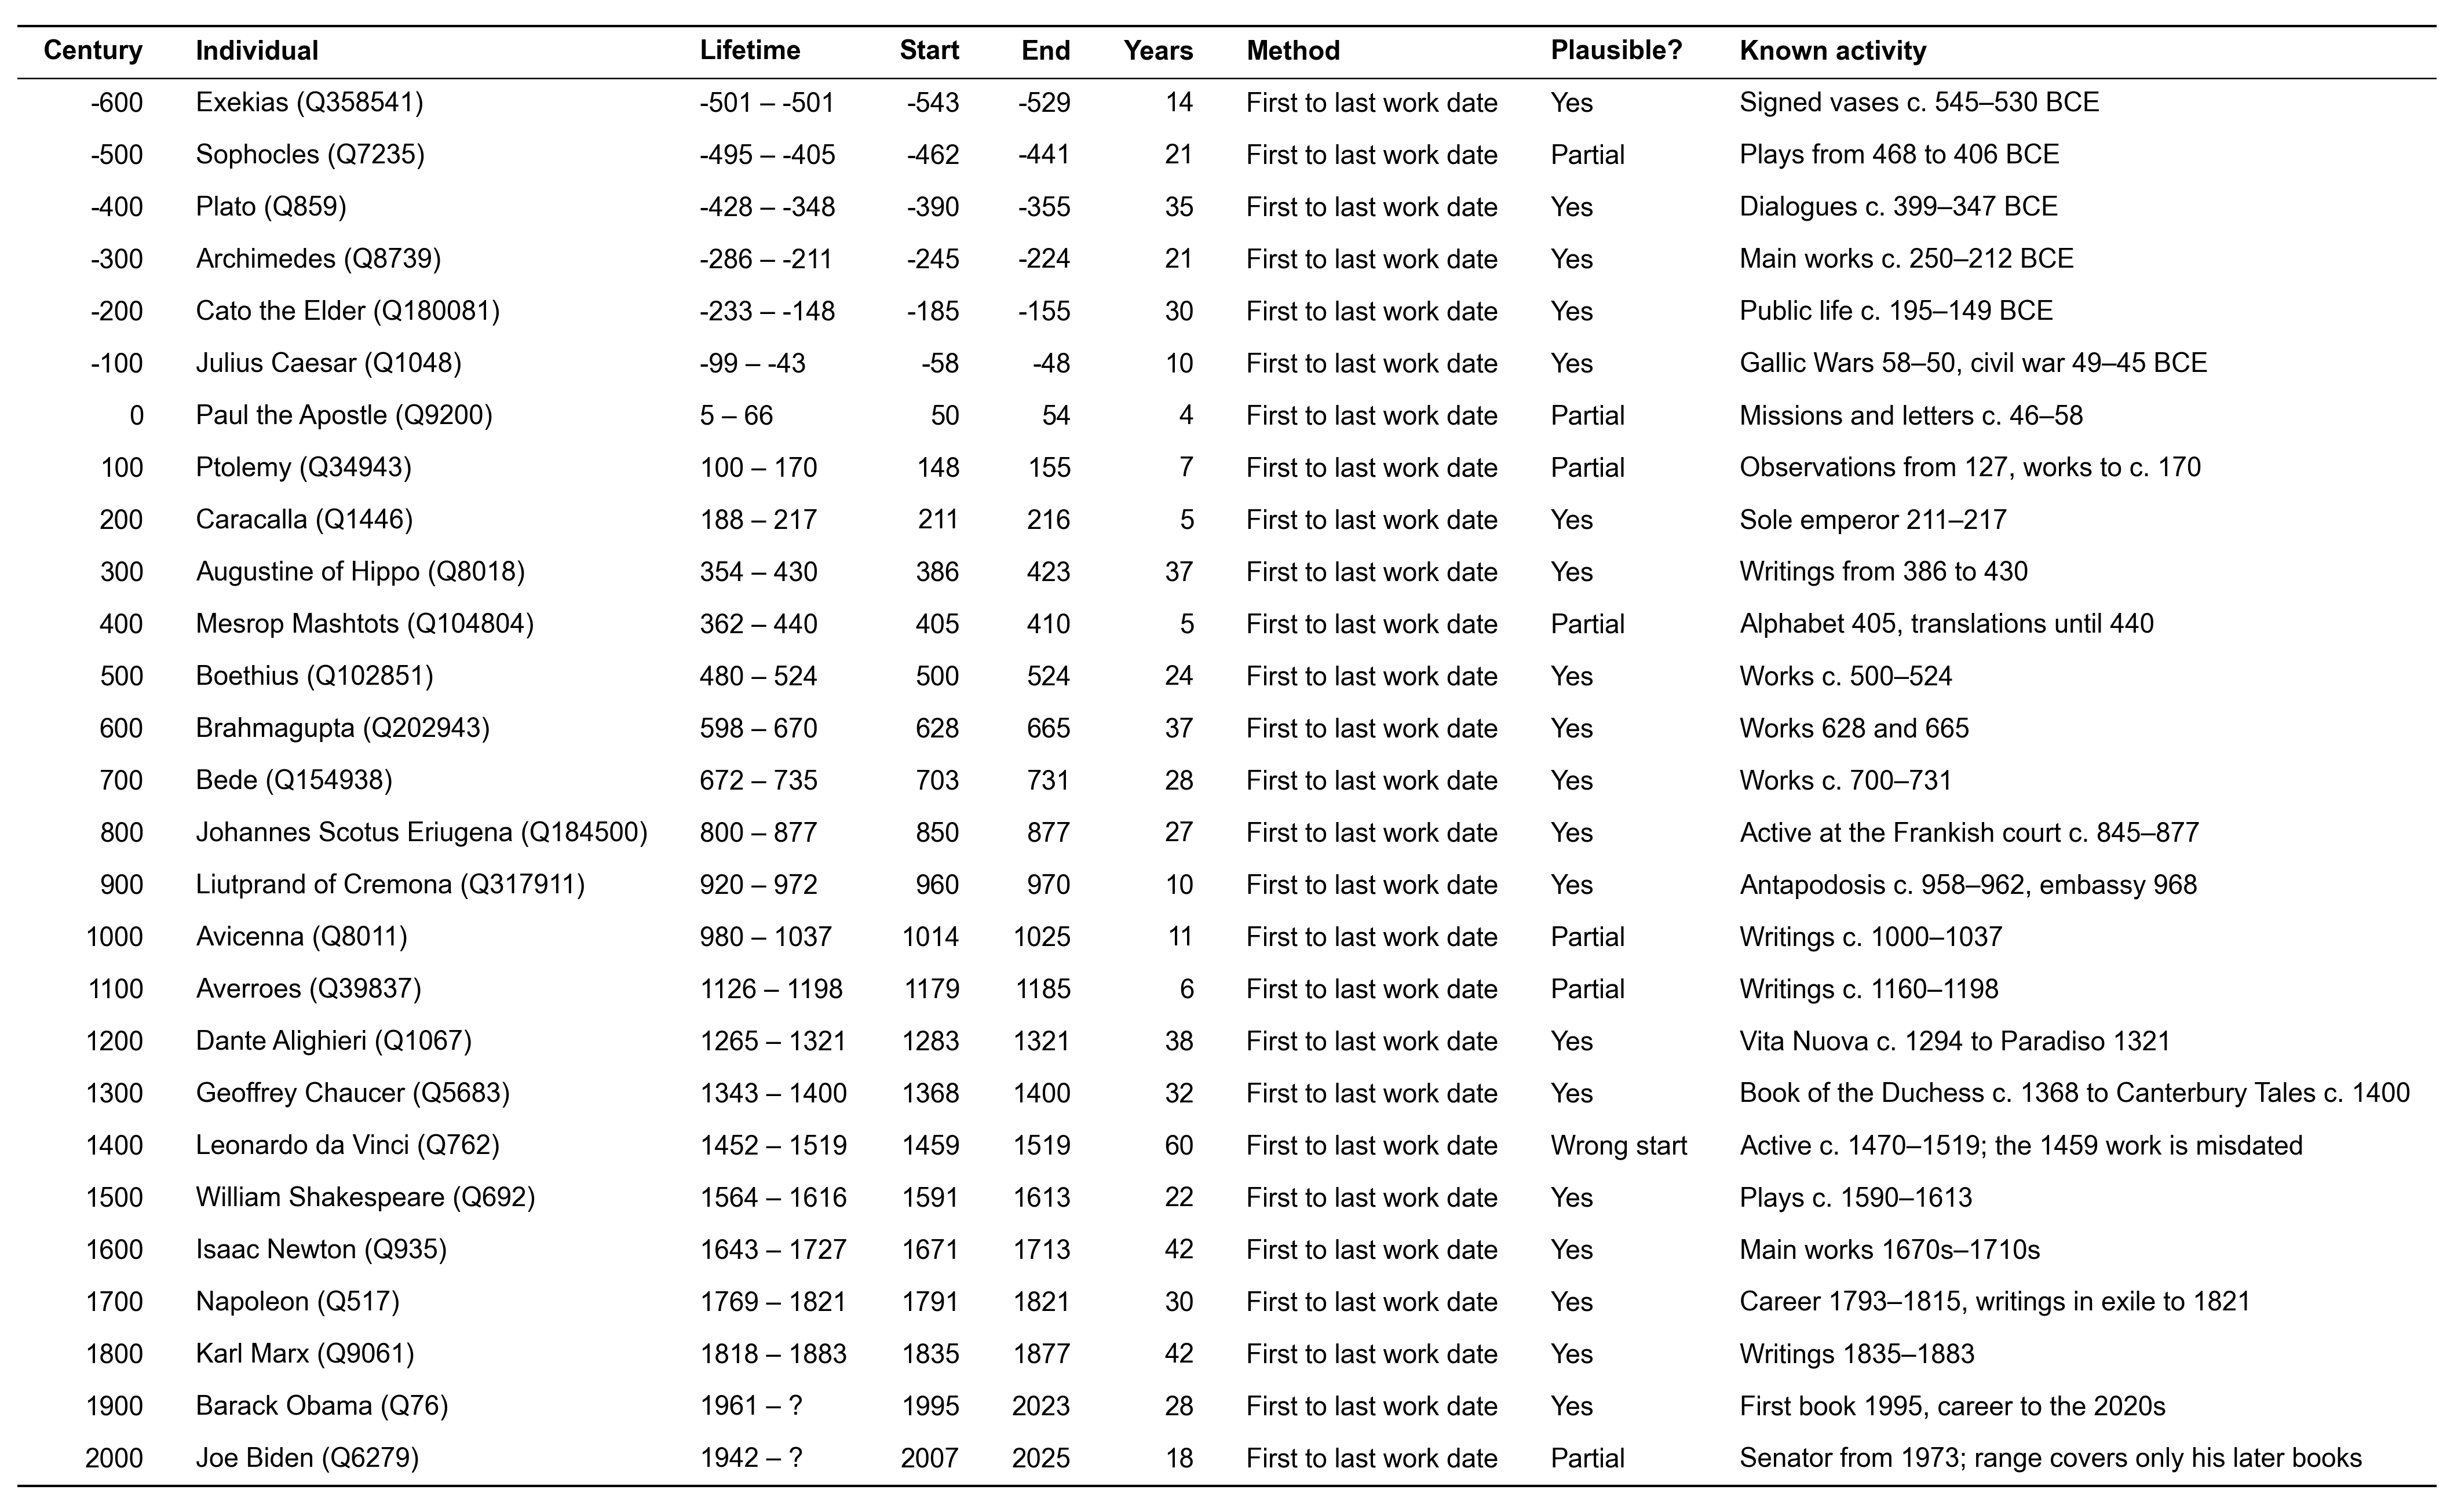

assessment,len
str,u32
"""Yes""",19
"""Partial""",7
"""Wrong start""",1


In [8]:
EVALUATION = {
    'Q358541': ('Yes', 'Signed vases c. 545–530 BCE'),
    'Q7235': ('Partial', 'Plays from 468 to 406 BCE'),
    'Q859': ('Yes', 'Dialogues c. 399–347 BCE'),
    'Q8739': ('Yes', 'Main works c. 250–212 BCE'),
    'Q180081': ('Yes', 'Public life c. 195–149 BCE'),
    'Q1048': ('Yes', 'Gallic Wars 58–50, civil war 49–45 BCE'),
    'Q9200': ('Partial', 'Missions and letters c. 46–58'),
    'Q34943': ('Partial', 'Observations from 127, works to c. 170'),
    'Q1446': ('Yes', 'Sole emperor 211–217'),
    'Q8018': ('Yes', 'Writings from 386 to 430'),
    'Q104804': ('Partial', 'Alphabet 405, translations until 440'),
    'Q102851': ('Yes', 'Works c. 500–524'),
    'Q202943': ('Yes', 'Works 628 and 665'),
    'Q154938': ('Yes', 'Works c. 700–731'),
    'Q184500': ('Yes', 'Active at the Frankish court c. 845–877'),
    'Q317911': ('Yes', 'Antapodosis c. 958–962, embassy 968'),
    'Q8011': ('Partial', 'Writings c. 1000–1037'),
    'Q39837': ('Partial', 'Writings c. 1160–1198'),
    'Q1067': ('Yes', 'Vita Nuova c. 1294 to Paradiso 1321'),
    'Q5683': ('Yes', 'Book of the Duchess c. 1368 to Canterbury Tales c. 1400'),
    'Q762': ('Wrong start', 'Active c. 1470–1519; the 1459 work is misdated'),
    'Q692': ('Yes', 'Plays c. 1590–1613'),
    'Q935': ('Yes', 'Main works 1670s–1710s'),
    'Q517': ('Yes', 'Career 1793–1815, writings in exile to 1821'),
    'Q9061': ('Yes', 'Writings 1835–1883'),
    'Q76': ('Yes', 'First book 1995, career to the 2020s'),
    'Q6279': ('Partial', 'Senator from 1973; range covers only his later books'),
}
assert set(EVALUATION) == set(examples['qid']), set(examples['qid']) ^ set(EVALUATION)

evaluated = examples.with_columns(
    pl.col('qid').replace_strict({qid: verdict for qid, (verdict, _) in EVALUATION.items()}).alias('assessment'),
    pl.col('qid').replace_strict({qid: comment for qid, (_, comment) in EVALUATION.items()}).alias('known_activity'),
)
show_table(evaluated.select(
    pl.col('century').cast(pl.String).alias('Century'),
    pl.col('individual').alias('Individual'),
    pl.col('lifetime').alias('Lifetime'),
    pl.col('start_year').cast(pl.String).alias('Start'),
    pl.col('end_year').cast(pl.String).alias('End'),
    pl.col('length').alias('Years'),
    pl.col('method').alias('Method'),
    pl.col('assessment').alias('Plausible?'),
    pl.col('known_activity').alias('Known activity'),
))
evaluated.group_by('assessment').len().sort('len', descending=True)

## Testing: one "fl." range per century
The same check for individuals whose range comes from "fl." with two dates in their description: the one with the most Wikimedia pages in each century, with the description the range was read from.

In [9]:
fl_examples = connection.execute(f'''
    SELECT floor(productivity.start_year / 100)::BIGINT * 100 AS century,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || productivity.qid || ')' AS individual,
           individual.entity.description AS description,
           productivity.start_year, productivity.end_year, productivity.length, productivity.method, productivity.qid
    FROM productivity
    JOIN individual ON individual.entity.qid = productivity.qid
    WHERE productivity.method = '"fl." with two dates'
      AND floor(productivity.start_year / 100) * 100 BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
    QUALIFY row_number() OVER (PARTITION BY floor(productivity.start_year / 100) ORDER BY len(individual.sitelink) DESC, productivity.qid) = 1
    ORDER BY century
''').pl()
fl_examples

century,individual,description,start_year,end_year,length,method,qid
i64,str,str,i64,i64,i64,str,str
-600,"""Chimaera Painter (Q65659082)""","""Corinthian artist fl. 600-575 BCE""",-600,-575,25,"""""fl."" with two dates""","""Q65659082"""
-500,"""Strattis (Q3975908)""","""Athenian poet of Old Comedy (fl. 412–380 BC)""",-412,-380,32,"""""fl."" with two dates""","""Q3975908"""
-400,"""Appius Claudius Caecus (Q297783)""","""Roman statesman and writer (fl. c. 312–279 BC)""",-312,-279,33,"""""fl."" with two dates""","""Q297783"""
-200,"""Oxyntas (Q7116043)""","""Numidian prince, son of King Jugurtha (fl. 104-89 BCE)""",-104,-89,15,"""""fl."" with two dates""","""Q7116043"""
100,"""Quan Cao (Q93388201)""","""fl. 169-184 or active 169-184""",169,184,15,"""""fl."" with two dates""","""Q93388201"""
300,"""Kuverami (Q111700841)""","""Queen regnant of Vaishali (Waythali) (fl. 334–341)""",334,341,7,"""""fl."" with two dates""","""Q111700841"""
500,"""Goar (Q48893117)""","""Goth captured by Byzantine empire (fl. 536-552)""",536,552,16,"""""fl."" with two dates""","""Q48893117"""
600,"""Dharmakirti (Q457990)""","""Indian Buddhist philosopher (fl.c.600–670)""",600,670,70,"""""fl."" with two dates""","""Q457990"""
800,"""Sergius-Tychicus (Q21055374)""","""Christian Paulician leader, fl. 801-835""",801,835,34,"""""fl."" with two dates""","""Q21055374"""


### Table: one "fl." range per century, with an assessment
Same scale as above, written by Claude from general historical knowledge, not checked against sources. Every range was also checked against the description it was read from; **Unknown** marks individuals too obscure to judge beyond that.

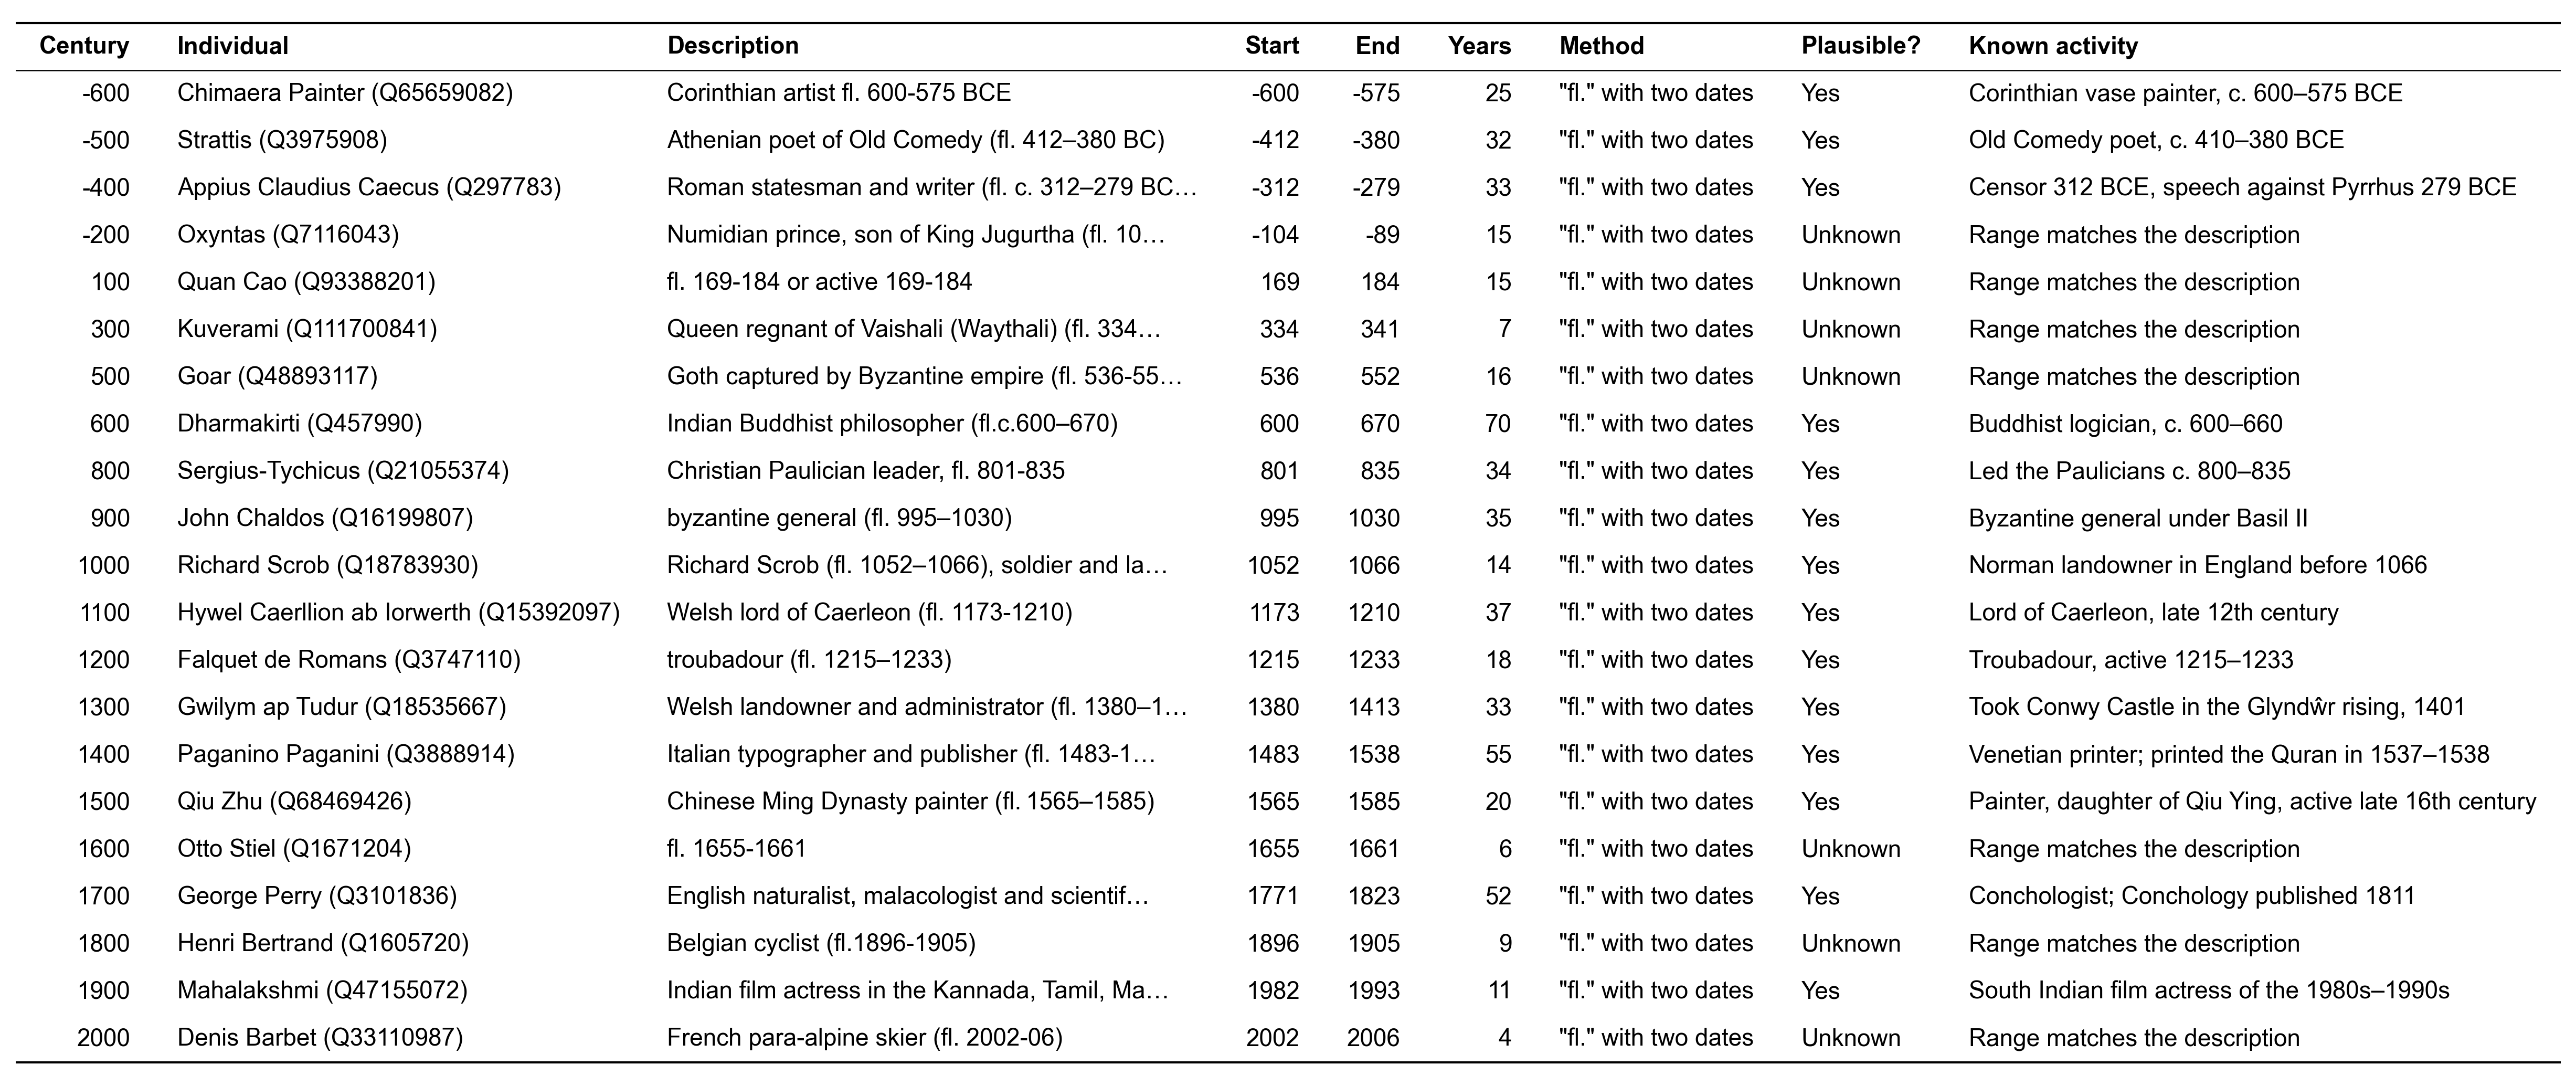

assessment,len
str,u32
"""Yes""",14
"""Unknown""",7


In [10]:
FL_EVALUATION = {
    'Q65659082': ('Yes', 'Corinthian vase painter, c. 600–575 BCE'),
    'Q3975908': ('Yes', 'Old Comedy poet, c. 410–380 BCE'),
    'Q297783': ('Yes', 'Censor 312 BCE, speech against Pyrrhus 279 BCE'),
    'Q7116043': ('Unknown', 'Range matches the description'),
    'Q93388201': ('Unknown', 'Range matches the description'),
    'Q111700841': ('Unknown', 'Range matches the description'),
    'Q48893117': ('Unknown', 'Range matches the description'),
    'Q457990': ('Yes', 'Buddhist logician, c. 600–660'),
    'Q21055374': ('Yes', 'Led the Paulicians c. 800–835'),
    'Q16199807': ('Yes', 'Byzantine general under Basil II'),
    'Q18783930': ('Yes', 'Norman landowner in England before 1066'),
    'Q15392097': ('Yes', 'Lord of Caerleon, late 12th century'),
    'Q3747110': ('Yes', 'Troubadour, active 1215–1233'),
    'Q18535667': ('Yes', 'Took Conwy Castle in the Glyndŵr rising, 1401'),
    'Q3888914': ('Yes', 'Venetian printer; printed the Quran in 1537–1538'),
    'Q68469426': ('Yes', 'Painter, daughter of Qiu Ying, active late 16th century'),
    'Q1671204': ('Unknown', 'Range matches the description'),
    'Q3101836': ('Yes', 'Conchologist; Conchology published 1811'),
    'Q1605720': ('Unknown', 'Range matches the description'),
    'Q47155072': ('Yes', 'South Indian film actress of the 1980s–1990s'),
    'Q33110987': ('Unknown', 'Range matches the description'),
}
assert set(FL_EVALUATION) == set(fl_examples['qid']), set(fl_examples['qid']) ^ set(FL_EVALUATION)

fl_evaluated = fl_examples.with_columns(
    pl.col('qid').replace_strict({qid: verdict for qid, (verdict, _) in FL_EVALUATION.items()}).alias('assessment'),
    pl.col('qid').replace_strict({qid: comment for qid, (_, comment) in FL_EVALUATION.items()}).alias('known_activity'),
    pl.when(pl.col('description').str.len_chars() > 45)
    .then(pl.col('description').str.slice(0, 45) + '…').otherwise(pl.col('description')).alias('description'),
)
show_table(fl_evaluated.select(
    pl.col('century').cast(pl.String).alias('Century'),
    pl.col('individual').alias('Individual'),
    pl.col('description').alias('Description'),
    pl.col('start_year').cast(pl.String).alias('Start'),
    pl.col('end_year').cast(pl.String).alias('End'),
    pl.col('length').alias('Years'),
    pl.col('method').alias('Method'),
    pl.col('assessment').alias('Plausible?'),
    pl.col('known_activity').alias('Known activity'),
))
fl_evaluated.group_by('assessment').len().sort('len', descending=True)